# Quantum Privacy Firewall - live demo notebook (Q-Hack India 2026)
**What this shows:** an experimental, Qiskit-based, pre-submission *circuit privacy audit*. It measures how well an attacker who sees only the final backend-compiled circuit can guess the algorithm family, then tries semantics-preserving rewrites that stay inside an overhead budget.

**Honest scope:** this is *not* encryption and *not* proven obfuscation. Every number below is computed by this repository from saved artifacts; nothing is typed in by hand. The IBM poster has limited public methods, so this is an independent IBM-inspired study, not an exact replication.

In [1]:
import sys, json, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, display
from qpf import config, pipeline, circuits, defenses, verification, selection, compilation
from qpf.config import art
PROFILE = "quick"     # "smoke" (~30 s) | "quick" (~2-3 min) | "full" (longest)
RERUN   = False       # True = recompute everything live in this notebook
cfg = config.load(PROFILE)
if RERUN or not (art(cfg, "results") / "release_gate.json").exists():
    pipeline.environment_snapshot(cfg); pipeline.build_manifest(cfg); pipeline.train_baseline(cfg)
    pipeline.run_defense(cfg); pipeline.evaluate_adaptive(cfg); pipeline.release_gate(cfg)
env = pipeline.jload(art(cfg, "manifests") / "environment.json")
print("profile:", PROFILE, "| backend:", env["backend"]["name"], env["backend"]["num_qubits"], "qubits | native ops:", env["backend"]["operations"])
print("qiskit", env["packages"]["qiskit"], "| qcec", env["packages"]["mqt.qcec"], "| seeds", env["seeds"])

profile: quick | backend: FakeNighthawk 120 qubits | native ops: ['cz', 'delay', 'id', 'if_else', 'measure', 'reset', 'rz', 'sx', 'x']
qiskit 2.5.2 | qcec 3.10.2 | seeds {'dataset': 7, 'transpile': 11, 'attacker': 0}


## 1. Dataset: grouped split by base circuit (no base circuit appears in two partitions)

In [2]:
man = pipeline.load_manifest(cfg)
display(man.groupby(["family", "split"]).size().unstack(fill_value=0))
print("widths:", sorted(man.width.unique()), "| frozen test ids saved:", len(pipeline.jload(art(cfg,'manifests')/'frozen_test_ids.json')['test_base_ids']))

split,test,train,val
family,,,
graph_ghz,2,6,2
grover,2,6,2
qaoa,2,6,2
qft,2,6,2
random,2,6,2


widths: [np.int64(6), np.int64(8)] | frozen test ids saved: 10


## 2. Baseline leakage experiment (M2): can an attacker name the algorithm family from the compiled circuit?

,macro-F1,balanced acc.
full features (RF),0.937,0.938
shuffled-label control,0.409,0.438
metadata-only control (width/depth/size/2Q),0.874,0.875
chance (1/K),0.250,NaN


95% bootstrap CI over test circuits (full features): [0.58, 1.0] | test class support: {'qft': 4, 'grover': 4, 'qaoa': 4, 'graph_ghz': 4}
repeated grouped re-splits: {'full': '0.888 +/- 0.034', 'metadata_only': '0.885 +/- 0.120', 'shuffled': '0.211 +/- 0.119'}
random-control circuits are labelled by the attacker as: {'graph_ghz': 12, 'qaoa': 8}
EXIT GATE: {'passed': True, 'metadata_confound_warning': True, 'rule': 'full macro-F1 > max(chance, shuffled) + 0.1; confound warning if metadata-only is within 0.02 of full (frozen split or repeated-split mean)'}


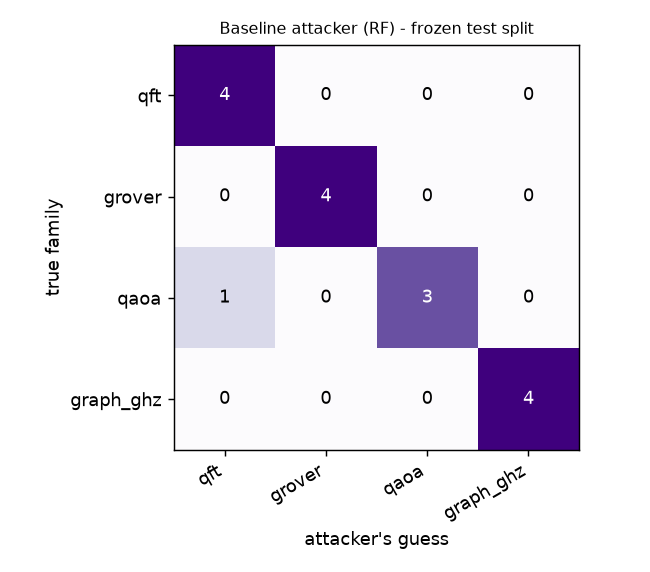

In [3]:
b = pipeline.jload(art(cfg, "results") / "baseline.json")
t = pd.DataFrame({"macro-F1": [b["full"]["macro_f1"], b["shuffled"]["macro_f1"], b["metadata_only"]["macro_f1"], b["chance"]],
                  "balanced acc.": [b["full"]["balanced_accuracy"], b["shuffled"]["balanced_accuracy"], b["metadata_only"]["balanced_accuracy"], np.nan]},
                 index=["full features (RF)", "shuffled-label control", "metadata-only control (width/depth/size/2Q)", "chance (1/K)"]).round(3)
display(t); print("95% bootstrap CI over test circuits (full features):", [round(x, 3) for x in b["full_macro_f1_ci95"]], "| test class support:", b["class_support_test"])
print("repeated grouped re-splits:", {k: f"{v['mean']:.3f} +/- {v['std']:.3f}" for k, v in b["repeated_grouped"].items()})
print("random-control circuits are labelled by the attacker as:", b["random_control_predictions"])
print("EXIT GATE:", b["exit_gate"]); display(Image(str(art(cfg, "figures") / "confusion_baseline.png")))

In [4]:
print("Cross-optimization-level transfer (macro-F1, disjoint circuits):"); display(pd.Series(b["transfer"]["opt"]).round(3).to_frame("macro-F1"))
print("Cross-size transfer:"); display(pd.Series(b["transfer"]["size"]).round(3).to_frame("macro-F1"))

Cross-optimization-level transfer (macro-F1, disjoint circuits):


,macro-F1
train0->test0,1.000
train0->test2,0.367
train2->test0,0.125
train2->test2,0.867


Cross-size transfer:


,macro-F1
train_w6->test_w6,0.617
train_w6->test_w8,1.000
train_w8->test_w6,0.500
train_w8->test_w8,1.000


## 3. Transformations with equivalence evidence (M3)

In [5]:
base = circuits.make_circuit("qaoa", 6, 123)
cand, layout = defenses.apply_strategy(base, "decomp+reorder+layout", 42)
print("ORIGINAL logical circuit:  gates =", dict(base.count_ops()), "| depth", base.depth()); print(base.draw("text", fold=120))
print("\nTRANSFORMED logical circuit: gates =", dict(cand.count_ops()), "| depth", cand.depth(), "| compile-time layout:", layout); print(cand.draw("text", fold=120))
v = verification.verify(base, cand); print("\nVERIFICATION:", v)
bad = cand.copy(); bad.x(0); print("DELIBERATELY WRONG candidate ->", verification.verify(base, bad))

ORIGINAL logical circuit:  gates = {'rzz': 27, 'rx': 18, 'h': 6} | depth 18
     ┌───┐                                                        ┌────────────┐                            »
q_0: ┤ H ├─■─────────────■───────────────────────────■────────────┤ Rx(1.3846) ├───────────────■────────────»
     ├───┤ │ZZ(0.33817)  │                           │            └────────────┘┌────────────┐ │ZZ(1.1584)  »
q_1: ┤ H ├─■─────────────┼─────────────■─────────────┼─────────────■────────────┤ Rx(1.3846) ├─■────────────»
     ├───┤               │             │             │ZZ(0.33817)  │            └────────────┘              »
q_2: ┤ H ├───────────────┼─────────────┼─────────────■─────────────┼─────────────■─────────────■────────────»
     ├───┤               │ZZ(0.33817)  │                           │ZZ(0.33817)  │             │            »
q_3: ┤ H ├───────────────■─────────────┼───────────────────────────■─────────────┼─────────────┼────────────»
     ├───┤                             │    

## 4. Candidate pool for one circuit, with budget decisions and rejection reasons (M4)

In [6]:
C = pd.read_csv(art(cfg, "features") / "candidates.csv")
tb = man[(man.family == "qaoa") & (man.split == "test")].base_id.iloc[0]; opt = sorted(C.opt[C.opt >= 0].unique())[-1]
g = C[(C.base_id == tb) & (C.opt == opt)].copy()
for bud in cfg["budgets"]["budgets"]: g[f"@{int(bud*100)}%"] = g.apply(lambda r: "OK" if selection.reject_reason(r, bud) == "" else selection.reject_reason(r, bud)[:34], axis=1)
print("base circuit:", tb, "| optimization level:", opt)
display(g[["strategy", "verify_status", "depth", "n2q", "active", "d_depth", "d_n2q"] + [c for c in g.columns if c.startswith("@")]].round(3).reset_index(drop=True))

base circuit: qaoa-w6-002 | optimization level: 2


,strategy,verify_status,depth,n2q,active,d_depth,d_n2q,@0%,@10%,@20%,@50%
0,baseline,PASS,185,87,7,0.000,0.000,OK,OK,OK,OK
1,layout,PASS,204,97,8,0.103,0.115,"over budget (depth +10.3%, n2q +11","over budget (depth +10.3%, n2q +11",OK,OK
2,decomp,PASS,173,77,6,-0.065,-0.115,OK,OK,OK,OK
3,reorder,PASS,185,87,7,0.000,0.000,OK,OK,OK,OK
4,decomp+reorder,PASS,172,77,6,-0.070,-0.115,OK,OK,OK,OK
5,decomp+layout,PASS,251,102,10,0.357,0.172,"over budget (depth +35.7%, n2q +17","over budget (depth +35.7%, n2q +17","over budget (depth +35.7%, active",OK
6,reorder+layout,PASS,209,94,8,0.130,0.080,"over budget (depth +13.0%, n2q +8.","over budget (depth +13.0%, active",OK,OK


## 5. Adaptive attacker evaluation (M5): attacker is *retrained* on protected training circuits, tested once on the frozen protected test split

BASELINE (frozen test split, K=4 classes, chance=0.25)
  full-feature RF macro-F1 = 0.937  CI95 0.580-1.000
  shuffled-label control  = 0.409   metadata-only control = 0.874
  exit gate passed = True   metadata confound warning = True
PROTECTED (adaptive attackers retrained on protected training groups; frozen test split)
  budget | adaptive RF | logreg | gboost | norm-aware | d.depth | d.2Q | protected%
      0% |       0.937 |  0.817 |  0.937 |      0.782 |     -2.0% |  -4.0% |     24%
     10% |       0.874 |  0.874 |  0.806 |      0.718 |     -1.8% |  -3.3% |     61%
     20% |       1.000 |  0.816 |  0.813 |      0.879 |     -1.1% |  -3.9% |     70%
     50% |       0.626 |  0.679 |  0.441 |      0.873 |      3.7% |  -1.4% |     86%


,budget,baseline F1,adaptive RF F1,RF CI95,paired delta (repeated splits),relative reduction (descriptive),search s/circuit
0,0%,0.937,0.937,"[0.58, 1.0]",-0.024 +/- 0.029,0.000,1.4
1,10%,0.937,0.874,"[0.48, 1.0]",0.017 +/- 0.033,0.067,1.4
2,20%,0.937,1.000,"[0.75, 1.0]",0.000 +/- 0.062,-0.068,1.4
3,50%,0.937,0.626,"[0.34, 0.78]",0.023 +/- 0.092,0.331,1.4


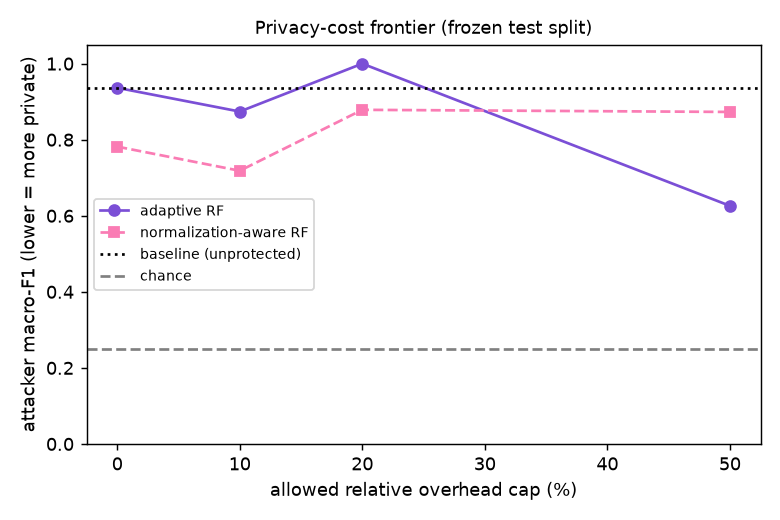

In [7]:
a = pipeline.jload(art(cfg, "results") / "adaptive.json"); print(pipeline.summary_text(cfg))
rows = []
for k, v in a["budgets"].items():
    rows.append({"budget": f"{float(k)*100:.0f}%", "baseline F1": a["baseline_test_macro_f1"], "adaptive RF F1": v["attackers"]["adaptive_rf"]["macro_f1"],
                 "RF CI95": [round(x, 2) for x in v["adaptive_rf_macro_f1_ci95"]], "paired delta (repeated splits)": f"{v['paired_repeated_grouped']['delta_mean']:.3f} +/- {v['paired_repeated_grouped']['delta_std']:.3f}",
                 "relative reduction (descriptive)": None if v["relative_reduction_descriptive"] is None else round(v["relative_reduction_descriptive"], 3),
                 "search s/circuit": round(v["candidate_search_time_s_per_circuit"], 1)})
display(pd.DataFrame(rows).round(3)); display(Image(str(art(cfg, "figures") / "privacy_cost_frontier.png")))

In [8]:
d = pipeline.jload(art(cfg, "results") / "defense.json")
print("verification verdicts:", d["verification_counts"], "| methods:", d["verification_method_counts"])
print("did the transformation survive compilation? (share of candidates whose observable features changed)")
display(pd.DataFrame(d["survival_rate_by_strategy"]).T.round(2))

verification verdicts: {'PASS': 600} | methods: {'identical_logical_circuit': 100, 'operator_equiv': 500}
did the transformation survive compilation? (share of candidates whose observable features changed)


,mean,count
decomp,0.93,100.0
decomp+layout,1.00,100.0
decomp+reorder,0.92,100.0
layout,1.00,100.0
reorder,0.00,100.0
reorder+layout,1.00,100.0


## 6. Release gate and honest reading of the results

In [9]:
print(json.dumps(pipeline.jload(art(cfg, "results") / "release_gate.json"), indent=2))

{
  "split_disjoint": true,
  "all_selected_verified": true,
  "surrogate_trained_on_train_only": true,
  "baseline_numbers_trace_to_predictions": true,
  "adaptive_numbers_trace_to_predictions": true,
  "no_nan_features_in_selected": true
}


**How to read this (no number is claimed beyond what is printed above):**
* The baseline result says whether leakage exists *in this controlled dataset*. Compare it with the shuffled-label and metadata-only controls, and note the confidence interval.
* Protection is only credible if the **retrained** attacker's macro-F1 drops relative to the baseline at a stated cost. If it does not, the correct reading is "no useful defense found at that budget" and the fallback is the *Quantum Circuit Leakage Auditor* (baseline audit only).
* Verification uses `Operator.equiv` up to the configured width and MQT QCEC above it; UNKNOWN is never counted as PASS. FakeNighthawk is a fake-backend snapshot, not live hardware.

## 7. Hackathon terminal demo: one victim, one attack, one verified rewrite

This cell runs `scripts/demo_attack.py`, which uses the saved final paper-full dataset. The attacker is trained with the victim source circuit excluded, then QPF generates verified rewrites and picks the lowest-confidence candidate inside the budget.


In [ ]:
import sys, subprocess
from pathlib import Path
from IPython.display import display, Markdown, HTML, Image

cmd = [sys.executable, "../scripts/demo_attack.py", "--generator", "qft_swaps", "--variant", "5", "--budget", "0.2", "--opt", "3"]
result = subprocess.run(cmd, cwd=Path.cwd(), text=True, capture_output=True, check=True)
display(HTML("<pre style='white-space:pre-wrap; font-size:12px; line-height:1.35; background:#0f172a; color:#e2e8f0; padding:14px; border-radius:8px;'>" + result.stdout.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;") + "</pre>"))


### Visual result summary

The first plot shows the attacker's confidence shifting away from the original intent class. The second plot shows every verified candidate: green points are within the overhead budget, gray points are over budget, and the star is the selected rewrite.


In [ ]:
from pathlib import Path
from IPython.display import Image, display

plot_dir = Path("../artifacts/demo_attack")
for name in ["attack_confidence_before_after.png", "candidate_confidence_vs_depth.png"]:
    path = plot_dir / name
    if path.exists():
        display(Image(filename=str(path)))
    else:
        print(f"missing {path}; run the demo cell above first")


### Candidate table for judges

This table is intentionally presentation-oriented: it highlights which rewrites passed equivalence, stayed inside the budget, and reduced confidence in the original attacker guess.


In [ ]:
import pandas as pd
from pathlib import Path

candidate_path = Path("../artifacts/demo_attack/candidate_table.csv")
if candidate_path.exists():
    C = pd.read_csv(candidate_path)
    show = C.copy()
    show["depth_overhead_%"] = (show["d_depth"] * 100).round(1)
    show["two_qubit_overhead_%"] = (show["d_2q"] * 100).round(1)
    show["confidence_in_original_guess_%"] = (show["conf"] * 100).round(1)
    show["eligible"] = show["ok"].map({True: "yes", False: "no"})
    cols = ["strategy", "seed", "verify", "depth_overhead_%", "two_qubit_overhead_%", "confidence_in_original_guess_%", "pred", "eligible"]
    display(
        show[cols]
        .style
        .background_gradient(subset=["confidence_in_original_guess_%"], cmap="RdYlGn_r")
        .background_gradient(subset=["depth_overhead_%", "two_qubit_overhead_%"], cmap="RdYlGn_r")
        .applymap(lambda v: "font-weight: 700; color: #047857" if v == "yes" else ("color: #b91c1c" if v == "no" else ""), subset=["eligible"])
        .format({"depth_overhead_%": "{:+.1f}", "two_qubit_overhead_%": "{:+.1f}", "confidence_in_original_guess_%": "{:.1f}"})
    )
else:
    print("Run the demo cell above first to create candidate_table.csv")


### Circuit drawings, if available

Qiskit can render colored circuit diagrams when the optional drawing stack is available. If the local environment lacks the extra renderer dependency, this cell falls back to compact text diagrams.


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown
from qpf import paper_circuits as PC, defenses
from qpf.paper_benchmark import load_cfg

cfg = load_cfg("full")
base = PC.make_source("qft_swaps", 24, 5)
selected_path = Path("../artifacts/demo_attack/selected_candidate.csv")
if selected_path.exists():
    sel = pd.read_csv(selected_path).iloc[0]
    cseed = 1000 * (cfg["defense"]["strategies"].index(sel.strategy) + 1) + int(sel.seed) + 1
    protected, _ = defenses.apply_strategy(base, sel.strategy, cseed, cfg["backend"])
else:
    protected = None

for title, circuit in [("Unprotected logical QFT source", base), ("Selected protected rewrite", protected)]:
    if circuit is None:
        continue
    display(Markdown(f"**{title}**"))
    try:
        display(circuit.draw(output="mpl", fold=80, style="iqp"))
    except Exception as exc:
        print(f"{title}: mpl drawing unavailable ({exc}); text fallback below")
        print(circuit.draw("text", fold=120))
